# 01 · A ontologia central de manufatura

**Objetivo:** entender as três peças da camada semântica e construir a primeira delas, a **ontologia central**.

| Peça | O que é | Neste repositório |
|---|---|---|
| **Ontologia** | o vocabulário: classes, relações e regras | `ontology/*.ttl` |
| **Grafo de conhecimento** | os fatos da planta descritos com esse vocabulário | `data/plant.ttl` |
| **Contratos de dados** | o que um registro precisa ter para entrar no grafo | `shapes/shapes.ttl` (notebook 03) |

A ontologia central é pequena de propósito: só o que **todos** os domínios precisam. Hierarquia ISA-95, pontos de dado e eventos. Produção, manutenção, qualidade, energia e estoque vêm depois, como **extensões** (notebook 02).

In [1]:
# Configuração: deixa a raiz do repositório no caminho de import
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import pandas as pd
pd.set_option("display.max_colwidth", 80)
from lab.graph import load_ontology, load_plant, query, MFG, PRD, MNT, QA, NRG, INV, ID

## 1. Carregando a ontologia central

O arquivo está em **Turtle**, o formato texto do RDF. Cada linha é uma tripla `sujeito predicado objeto`.

In [2]:
core = load_ontology(domains=[])
print(f"{len(core)} triplas na ontologia central\n")
print(open("../ontology/core.ttl", encoding="utf-8").read()[1200:2600])

82 triplas na ontologia central

ierarchy that has a stable identity." .

mfg:Enterprise  a owl:Class ; rdfs:subClassOf mfg:Asset ; rdfs:label "Enterprise" .
mfg:Site        a owl:Class ; rdfs:subClassOf mfg:Asset ; rdfs:label "Site" .
mfg:Area        a owl:Class ; rdfs:subClassOf mfg:Asset ; rdfs:label "Area" .
mfg:Line        a owl:Class ; rdfs:subClassOf mfg:Asset ; rdfs:label "Production line" .
mfg:Equipment   a owl:Class ; rdfs:subClassOf mfg:Asset ; rdfs:label "Equipment" ;
    rdfs:comment "ISA-95 work cell / unit: a machine that runs, stops and produces." .

mfg:partOf a owl:ObjectProperty, owl:TransitiveProperty ;
    rdfs:label "part of" ;
    rdfs:comment "Containment in the equipment hierarchy. Transitive: a filler partOf line 1 partOf area partOf site." ;
    rdfs:domain mfg:Asset ; rdfs:range mfg:Asset .

mfg:hasPart a owl:ObjectProperty ; owl:inverseOf mfg:partOf ; rdfs:label "has part" .

mfg:assetId a owl:DatatypeProperty, owl:FunctionalProperty ;
    rdfs:label "asse

## 2. As classes e a hierarquia de classes

In [3]:
classes = query(core, '''
SELECT ?classe ?mae ?descricao WHERE {
  ?c a <http://www.w3.org/2002/07/owl#Class> ; rdfs:label ?classe .
  OPTIONAL { ?c rdfs:subClassOf/rdfs:label ?mae }
  OPTIONAL { ?c rdfs:comment ?descricao }
} ORDER BY ?mae ?classe''')
pd.DataFrame(classes)

,classe,descricao,mae
0,Asset,Anything in the equipment hierarchy that has a stable identity.,NaN
1,Data point,"A measured or derived value that belongs to an asset (a PLC tag, a computed ...",NaN
2,Event,"Something that happened to an asset at a point in time (state change, order ...",NaN
3,Area,NaN,Asset
4,Enterprise,NaN,Asset
5,Equipment,"ISA-95 work cell / unit: a machine that runs, stops and produces.",Asset
6,Production line,NaN,Asset
7,Site,NaN,Asset
8,State change,NaN,Event


**Leitura:** `Enterprise`, `Site`, `Area`, `Line` e `Equipment` são todos subclasses de `Asset`. Isso permite perguntar "todos os ativos" sem listar os cinco tipos, e garante que qualquer coisa da hierarquia tenha um `assetId`.

`StateChange` é subclasse de `Event`: toda extensão que criar um evento novo (parada, ordem de produção, inspeção) herda `occurredOn`, `startTime` e `endTime`.

## 3. As relações (propriedades)

In [4]:
props = query(core, '''
SELECT ?propriedade ?tipo ?de ?para WHERE {
  ?p rdfs:label ?propriedade ; a ?t .
  FILTER(?t IN (<http://www.w3.org/2002/07/owl#ObjectProperty>, <http://www.w3.org/2002/07/owl#DatatypeProperty>))
  BIND(STRAFTER(STR(?t), "#") AS ?tipo)
  OPTIONAL { ?p rdfs:domain/rdfs:label ?de }
  OPTIONAL { ?p rdfs:range ?r . BIND(REPLACE(STR(?r), "^.*[#/]", "") AS ?para) }
} ORDER BY ?tipo ?propriedade''')
pd.DataFrame(props)

,propriedade,tipo,de,para
0,UNS topic,DatatypeProperty,Data point,string
1,asset id,DatatypeProperty,Asset,string
2,end time,DatatypeProperty,Event,dateTime
3,last update,DatatypeProperty,Data point,dateTime
4,last value,DatatypeProperty,Data point,NaN
5,start time,DatatypeProperty,Event,dateTime
6,to state,DatatypeProperty,State change,string
7,unit,DatatypeProperty,Data point,string
8,has data point,ObjectProperty,Asset,DataPoint
9,has part,ObjectProperty,NaN,NaN


* **ObjectProperty** liga duas coisas (`partOf` liga um ativo a outro ativo).
* **DatatypeProperty** liga uma coisa a um valor (`unsTopic` liga um ponto de dado a uma string).
* `partOf` é **transitiva**: se a enchedora é parte da linha 1 e a linha 1 é parte da área de envase, a enchedora também é parte da área. Isso evita gravar todas as relações indiretas.

## 4. A ontologia aplicada: a planta de exemplo

Agora carregamos os **fatos** (`data/plant.ttl`) sobre o vocabulário. Uma empresa fictícia com duas plantas, três linhas e três máquinas por linha.

In [5]:
g = load_plant()
print(f"{len(g)} triplas (ontologia + dados)")
ativos = query(g, '''
SELECT ?tipo (COUNT(?a) AS ?quantidade) WHERE {
  ?a a ?c . ?c rdfs:subClassOf* mfg:Asset ; rdfs:label ?tipo .
  FILTER(STRSTARTS(STR(?a), STR(id:)))
} GROUP BY ?tipo ORDER BY DESC(?quantidade)''')
pd.DataFrame(ativos)

698 triplas (ontologia + dados)


,tipo,quantidade
0,Equipment,9
1,Production line,3
2,Component,3
3,Site,2
4,Area,2
5,Enterprise,1


Repare em `rdfs:subClassOf*`: o asterisco percorre a hierarquia de classes, então `Component` (definido na extensão de manutenção) entra na conta como ativo sem que a consulta precise saber que ele existe.

## 5. A hierarquia ISA-95 como grafo

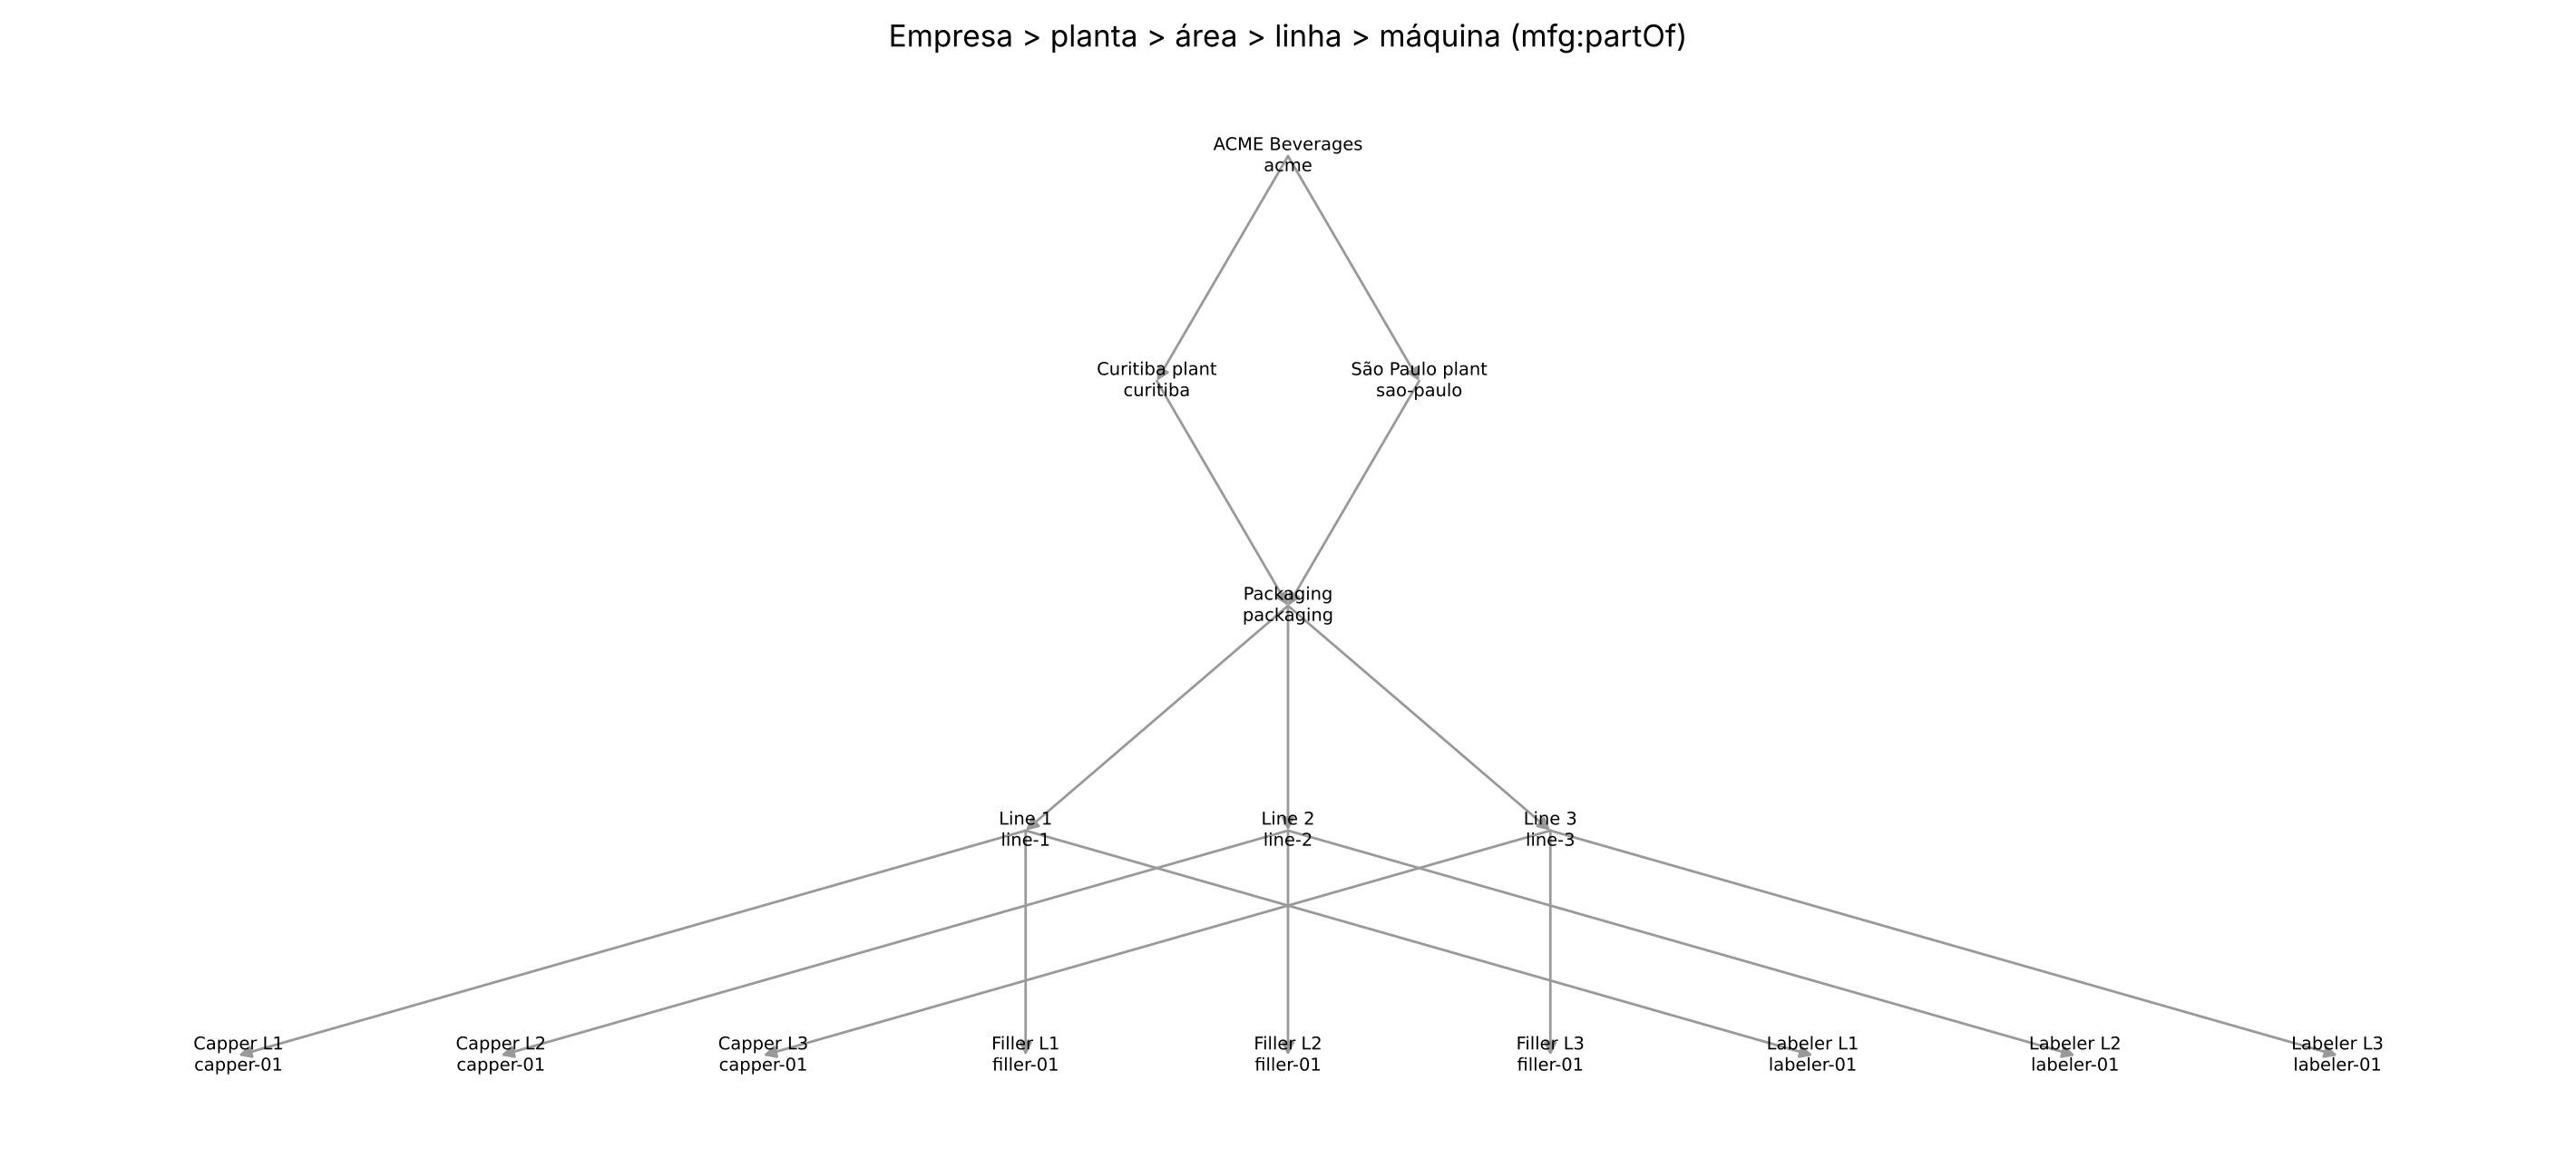

In [6]:
import networkx as nx, matplotlib.pyplot as plt
G = nx.DiGraph()
for filho, pai in g.subject_objects(MFG.partOf):
    if (filho, None, MNT.Component) in g: continue
    nome = lambda n: str(g.value(n, g.namespace_manager.expand_curie("rdfs:label")))
    G.add_edge(nome(pai) + "\n" + str(pai).rsplit("/", 1)[-1], nome(filho) + "\n" + str(filho).rsplit("/", 1)[-1])
niveis = {n: 0 for n in G if G.in_degree(n) == 0}
for n in nx.topological_sort(G):
    for s in G.successors(n): niveis[s] = niveis[n] + 1
camadas = {}
for n, l in niveis.items(): camadas.setdefault(l, []).append(n)
pos = {n: (i - len(ns) / 2, -l) for l, ns in camadas.items() for i, n in enumerate(sorted(ns))}
plt.figure(figsize=(14, 6))
nx.draw(G, pos, with_labels=True, node_size=0, font_size=7, arrows=True, edge_color="#999")
plt.title("Empresa > planta > área > linha > máquina (mfg:partOf)"); plt.show()

## 6. Transitividade na prática

Pergunta: **"tudo o que existe na planta de São Paulo"**. Ninguém gravou "enchedora partOf São Paulo"; o caminho `partOf+` (um ou mais saltos) encontra.

In [7]:
from lab import queries as q
pd.DataFrame(query(g, q.ASSETS_IN_SITE)).assign(asset=lambda d: d.asset.str.split("/id/").str[1], type=lambda d: d.type.str.split("#").str[1])

,asset,type,label
0,acme/sao-paulo/packaging,Area,Packaging
1,acme/sao-paulo/packaging/line-1,Line,Line 1
2,acme/sao-paulo/packaging/line-1/capper-01,Equipment,Capper L1
3,acme/sao-paulo/packaging/line-1/filler-01,Equipment,Filler L1
4,acme/sao-paulo/packaging/line-1/filler-01/main-motor,Component,Main Motor
5,acme/sao-paulo/packaging/line-1/filler-01/seal-kit,Component,Seal Kit
6,acme/sao-paulo/packaging/line-1/filler-01/valve-block,Component,Valve Block
7,acme/sao-paulo/packaging/line-1/labeler-01,Equipment,Labeler L1
8,acme/sao-paulo/packaging/line-2,Line,Line 2
9,acme/sao-paulo/packaging/line-2/capper-01,Equipment,Capper L2


São 12 ativos: a área, duas linhas, seis máquinas e três **componentes** da enchedora da linha 1, que vivem dois níveis abaixo da linha.

## Resumo

* A ontologia central define **identidade** (`assetId`), **contenção** (`partOf`, transitiva), **pontos de dado** (com o tópico do UNS) e **eventos**.
* Classes formam hierarquias (`subClassOf`), e consultas com `*` e `+` aproveitam isso sem conhecer cada tipo.
* Tudo que vier depois (produção, manutenção, qualidade...) **pendura** nesse núcleo, em vez de criar seu próprio modelo de máquina.